In [1]:
# ==========================================================
# 1. Imports
# ==========================================================

import pandas as pd
import numpy as np

import pymc as pm
import arviz as az

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from IPython.display import display

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

g++ not available, if using conda: `conda install gxx`


Libraries imported successfully.


In [2]:
# ==========================================================
# 2. Load Modelling Dataset
# ==========================================================

df = pd.read_parquet(
    r"C:\Users\trish\OneDrive - University of Bristol\summer project\TS\Data\active_lives_modelling_dataset.parquet"
)

print(f"Dataset Shape: {df.shape}")

display(df.head())

Dataset Shape: (135497, 20)


,survey_year,borough,Age_Group,Gend3,Eth7,Disab3,Educ6,health,wt_final,MEMS7_ALL,Activity_Level,MONTHS_12_WALKALL_C01,MONTHS_12_CYCALL_C02,MONTHS_12_ACTTRAV_C03,MONTHS_12_DANCEALL_C04,MONTHS_12_TEAMSPORT_C05,MONTHS_12_RACKETSPORT_C06,MONTHS_12_ADVWATERSPORT_C07,MONTHS_12_LEISURE_C08,MONTHS_12_COMBATTARGET_C09
0,2015-16,Barking and Dagenham,25-44,Female,Other ethnic group,No disability,Level 4 or above,NaN,0.727690,290.0,Active,Yes,NaN,Yes,No,No,No,No,No,No
1,2015-16,Barking and Dagenham,NaN,Female,Black,Non-limiting disability,Level 4 or above,NaN,1.120481,370.0,Active,Yes,NaN,Yes,Yes,No,No,No,No,No
2,2015-16,Barking and Dagenham,25-44,Male,South Asian,No disability,Level 4 or above,NaN,0.708328,120.0,Fairly Active,Yes,NaN,No,No,Yes,No,No,No,No
3,2015-16,Barking and Dagenham,45-64,Male,White British,No disability,Level 2 and equivalents,NaN,1.165601,0.0,Inactive,Yes,NaN,Yes,No,No,No,No,No,No
4,2015-16,Barking and Dagenham,45-64,Male,South Asian,No disability,Another type of qualification,NaN,4.191322,0.0,Inactive,Yes,NaN,Yes,No,No,No,No,No,No


In [3]:
# ==========================================================
# 3. Select Variables for Activity Level Model
# ==========================================================

model_df = df[
    [
        "survey_year",
        "borough",
        "Age_Group",
        "Gend3",
        "Eth7",
        "Disab3",
        "Educ6",
        "health",
        "wt_final",
        "Activity_Level"
    ]
].copy()

print(f"Model dataset shape: {model_df.shape}")

display(model_df.head())

Model dataset shape: (135497, 10)


,survey_year,borough,Age_Group,Gend3,Eth7,Disab3,Educ6,health,wt_final,Activity_Level
0,2015-16,Barking and Dagenham,25-44,Female,Other ethnic group,No disability,Level 4 or above,NaN,0.727690,Active
1,2015-16,Barking and Dagenham,NaN,Female,Black,Non-limiting disability,Level 4 or above,NaN,1.120481,Active
2,2015-16,Barking and Dagenham,25-44,Male,South Asian,No disability,Level 4 or above,NaN,0.708328,Fairly Active
3,2015-16,Barking and Dagenham,45-64,Male,White British,No disability,Level 2 and equivalents,NaN,1.165601,Inactive
4,2015-16,Barking and Dagenham,45-64,Male,South Asian,No disability,Another type of qualification,NaN,4.191322,Inactive


In [4]:
# ==========================================================
# 4. Prepare Final Dataset
# ==========================================================

model_df = model_df.drop(columns=["health"])
model_df = model_df.drop(columns=["wt_final"])

print(f"Model dataset shape: {model_df.shape}")

display(model_df.head())

Model dataset shape: (135497, 8)


,survey_year,borough,Age_Group,Gend3,Eth7,Disab3,Educ6,Activity_Level
0,2015-16,Barking and Dagenham,25-44,Female,Other ethnic group,No disability,Level 4 or above,Active
1,2015-16,Barking and Dagenham,NaN,Female,Black,Non-limiting disability,Level 4 or above,Active
2,2015-16,Barking and Dagenham,25-44,Male,South Asian,No disability,Level 4 or above,Fairly Active
3,2015-16,Barking and Dagenham,45-64,Male,White British,No disability,Level 2 and equivalents,Inactive
4,2015-16,Barking and Dagenham,45-64,Male,South Asian,No disability,Another type of qualification,Inactive


In [5]:
# ==========================================================
# Missing Values After Removing Health
# ==========================================================

missing = (
    model_df.isna()
            .sum()
            .to_frame("Missing")
)

missing["Percent"] = (
    missing["Missing"] / len(model_df) * 100
).round(2)

display(
    missing[missing["Missing"] > 0]
    .sort_values("Percent", ascending=False)
)

,Missing,Percent
Eth7,9181,6.78
Disab3,9137,6.74
Educ6,8766,6.47
Age_Group,1327,0.98
Gend3,303,0.22


In [6]:
# ==========================================================
# 5. Handle Missing Values
# ==========================================================

categorical_predictors = [
    "Age_Group",
    "Gend3",
    "Eth7",
    "Disab3",
    "Educ6"
]

for col in categorical_predictors:
    model_df[col] = model_df[col].cat.add_categories("Missing")
    model_df[col] = model_df[col].fillna("Missing")

print("Missing values replaced with 'Missing' category.")

Missing values replaced with 'Missing' category.


In [7]:
# ==========================================================
# Validate Missing Values
# ==========================================================

missing = (
    model_df.isna()
            .sum()
            .to_frame("Missing")
)

missing["Percent"] = (
    missing["Missing"] / len(model_df) * 100
).round(2)

display(missing)

,Missing,Percent
survey_year,0,0.0
borough,0,0.0
Age_Group,0,0.0
Gend3,0,0.0
Eth7,0,0.0
Disab3,0,0.0
Educ6,0,0.0
Activity_Level,0,0.0


In [8]:
model_df["Educ6"].value_counts(dropna=False)

Educ6
Level 4 or above                 83670
Level 2 and equivalents          14427
Level 3 and equivalents          14033
Missing                           8766
No qualifications                 7656
Another type of qualification     5023
Level 1 and below                 1922
Name: count, dtype: int64

In [9]:
model_df["Eth7"].value_counts(dropna=False)

Eth7
White British         68903
White Other           20689
South Asian           17662
Missing                9181
Black                  8682
Mixed                  4101
Other ethnic group     3658
Chinese                2621
Name: count, dtype: int64

In [10]:
model_df["Disab3"].value_counts(dropna=False)


Disab3
No disability              88353
Non-limiting disability    19531
Limiting disability        18476
Missing                     9137
Name: count, dtype: int64

In [11]:
model_df["Age_Group"].value_counts(dropna=False)


Age_Group
25-44      53216
45-64      43555
65+        26289
16-24      11110
Missing     1327
Name: count, dtype: int64

In [12]:
model_df["Gend3"].value_counts(dropna=False)

Gend3
Female     75875
Male       58849
Other        470
Missing      303
Name: count, dtype: int64

In [13]:
# ==========================================================
# 6. Define Category Order
# ==========================================================

# Age Group (ordered)
age_order = [
    "16-24",
    "25-44",
    "45-64",
    "65+",
    "Missing"
]

# Education Level (ordered)
education_order = [
    "No qualifications",
    "Level 1 and below",
    "Level 2 and equivalents",
    "Level 3 and equivalents",
    "Level 4 or above",
    "Another type of qualification",
    "Missing"
]

# Activity Level (Target - ordered)
activity_order = [
    "Inactive",
    "Fairly Active",
    "Active"
]

In [14]:
# ==========================================================
# 7. Convert Ordered Variables to Ordered Categories
# ==========================================================

# Age Group
model_df["Age_Group"] = pd.Categorical(
    model_df["Age_Group"],
    categories=age_order,
    ordered=True
)

# Activity Level (Target)
model_df["Activity_Level"] = pd.Categorical(
    model_df["Activity_Level"],
    categories=activity_order,
    ordered=True
)

In [15]:
# ==========================================================
# 8. Verify Ordered Categories
# ==========================================================

print("Age Group Order:")
print(model_df["Age_Group"].cat.categories)

print("\nActivity Level Order:")
print(model_df["Activity_Level"].cat.categories)

Age Group Order:
Index(['16-24', '25-44', '45-64', '65+', 'Missing'], dtype='object')

Activity Level Order:
Index(['Inactive', 'Fairly Active', 'Active'], dtype='object')


In [16]:
# ==========================================================
# 9. Encode Ordered Variables
# ==========================================================

# Ordinal encoding
model_df["Age_Code"] = model_df["Age_Group"].cat.codes

# Target encoding
model_df["Activity_Code"] = model_df["Activity_Level"].cat.codes

In [17]:
model_df[
    ["Age_Group", "Age_Code",
     "Activity_Level", "Activity_Code"]
].head(10)

,Age_Group,Age_Code,Activity_Level,Activity_Code
0,25-44,1,Active,2
1,Missing,4,Active,2
2,25-44,1,Fairly Active,1
3,45-64,2,Inactive,0
4,45-64,2,Inactive,0
5,16-24,0,Active,2
6,45-64,2,Active,2
7,45-64,2,Active,2
8,65+,3,Active,2
9,25-44,1,Active,2


In [18]:
# ==========================================================
# 10. Encode Borough and Survey Year
# ==========================================================

# Borough index (Random Effect)
model_df["Borough_Code"] = model_df["borough"].cat.codes

# Survey Year index (Fixed Effect)
model_df["Year_Code"] = model_df["survey_year"].cat.codes

In [19]:
model_df[
    [
        "borough",
        "Borough_Code",
        "survey_year",
        "Year_Code"
    ]
].head(10)

,borough,Borough_Code,survey_year,Year_Code
0,Barking and Dagenham,0,2015-16,0
1,Barking and Dagenham,0,2015-16,0
2,Barking and Dagenham,0,2015-16,0
3,Barking and Dagenham,0,2015-16,0
4,Barking and Dagenham,0,2015-16,0
5,Barking and Dagenham,0,2015-16,0
6,Barking and Dagenham,0,2015-16,0
7,Barking and Dagenham,0,2015-16,0
8,Barking and Dagenham,0,2015-16,0
9,Barking and Dagenham,0,2015-16,0


In [20]:
print("Number of Boroughs:", model_df["Borough_Code"].nunique())
print("Number of Survey Years:", model_df["Year_Code"].nunique())

Number of Boroughs: 32
Number of Survey Years: 8


In [21]:
# ==========================================================
# 11. Encode Nominal Predictors
# ==========================================================

# Gender
model_df["Gender_Code"] = model_df["Gend3"].cat.codes

# Ethnicity
model_df["Ethnicity_Code"] = model_df["Eth7"].cat.codes

# Disability
model_df["Disability_Code"] = model_df["Disab3"].cat.codes

# Education
model_df["Education_Code"] = model_df["Educ6"].cat.codes

In [22]:
model_df[
    [
        "Gend3",
        "Gender_Code",
        "Eth7",
        "Ethnicity_Code",
        "Disab3",
        "Disability_Code",
        "Educ6",
        "Education_Code"
    ]
].head(10)

,Gend3,Gender_Code,Eth7,Ethnicity_Code,Disab3,Disability_Code,Educ6,Education_Code
0,Female,0,Other ethnic group,3,No disability,1,Level 4 or above,4
1,Female,0,Black,0,Non-limiting disability,2,Level 4 or above,4
2,Male,1,South Asian,4,No disability,1,Level 4 or above,4
3,Male,1,White British,5,No disability,1,Level 2 and equivalents,2
4,Male,1,South Asian,4,No disability,1,Another type of qualification,0
5,Male,1,South Asian,4,No disability,1,Level 3 and equivalents,3
6,Male,1,White British,5,Non-limiting disability,2,Level 4 or above,4
7,Male,1,Mixed,2,No disability,1,Level 2 and equivalents,2
8,Female,0,White British,5,Missing,3,Missing,6
9,Female,0,White British,5,Non-limiting disability,2,Level 4 or above,4


In [23]:
# ==========================================================
# Train/Test Split
# ==========================================================

train_df = model_df[
    model_df["survey_year"] != "2022-23"
].copy()

test_df = model_df[
    model_df["survey_year"] == "2022-23"
].copy()

print(f"Training observations : {len(train_df):,}")
print(f"Testing observations  : {len(test_df):,}")

print("\nTraining years:")
print(train_df["survey_year"].unique())

print("\nTesting year:")
print(test_df["survey_year"].unique())

Training observations : 118,982
Testing observations  : 16,515

Training years:
['2015-16', '2016-17', '2017-18', '2018-19', '2019-20', '2020-21', '2021-22']
Categories (8, object): ['2015-16', '2016-17', '2017-18', '2018-19', '2019-20', '2020-21', '2021-22', '2022-23']

Testing year:
['2022-23']
Categories (8, object): ['2015-16', '2016-17', '2017-18', '2018-19', '2019-20', '2020-21', '2021-22', '2022-23']


In [24]:
# ==========================================================
# Prepare Training Data
# ==========================================================

# Response
y_train = train_df["Activity_Code"].values
y_test = test_df["Activity_Code"].values

# Grouping variable
borough_train = train_df["Borough_Code"].values
borough_test = test_df["Borough_Code"].values

# Fixed effects

age_train = train_df["Age_Code"].values
age_test = test_df["Age_Code"].values

gender_train = train_df["Gender_Code"].values
gender_test = test_df["Gender_Code"].values

ethnicity_train = train_df["Ethnicity_Code"].values
ethnicity_test = test_df["Ethnicity_Code"].values

disability_train = train_df["Disability_Code"].values
disability_test = test_df["Disability_Code"].values

education_train = train_df["Education_Code"].values
education_test = test_df["Education_Code"].values

year_train = train_df["Year_Code"].values
year_test = test_df["Year_Code"].values

# Dimensions
n_boroughs = model_df["Borough_Code"].nunique()

n_age = model_df["Age_Code"].nunique()
n_gender = model_df["Gender_Code"].nunique()
n_ethnicity = model_df["Ethnicity_Code"].nunique()
n_disability = model_df["Disability_Code"].nunique()
n_education = model_df["Education_Code"].nunique()
n_year = model_df["Year_Code"].nunique()

In [25]:
import pymc as pm

with pm.Model() as activity_model:

    # -------------------------
    # Mutable data
    # -------------------------
    borough = pm.Data("borough", borough_train)
    age = pm.Data("age", age_train)
    gender = pm.Data("gender", gender_train)
    ethnicity = pm.Data("ethnicity", ethnicity_train)
    disability = pm.Data("disability", disability_train)
    education = pm.Data("education", education_train)
    year = pm.Data("year", year_train)

    # -------------------------
    # Priors
    # -------------------------
    sigma_borough = pm.HalfNormal("sigma_borough", sigma=1)

    borough_effect = pm.Normal(
        "borough_effect",
        mu=0,
        sigma=sigma_borough,
        shape=n_boroughs
    )

    intercept = pm.Normal("intercept", 0, 2)

    age_effect = pm.Normal("age_effect", 0, 1, shape=n_age)
    gender_effect = pm.Normal("gender_effect", 0, 1, shape=n_gender)
    ethnicity_effect = pm.Normal("ethnicity_effect", 0, 1, shape=n_ethnicity)
    disability_effect = pm.Normal("disability_effect", 0, 1, shape=n_disability)
    education_effect = pm.Normal("education_effect", 0, 1, shape=n_education)
    year_effect = pm.Normal("year_effect", 0, 1, shape=n_year)

    # -------------------------
    # Linear predictor
    # -------------------------
    eta = (
        intercept
        + borough_effect[borough]
        + age_effect[age]
        + gender_effect[gender]
        + ethnicity_effect[ethnicity]
        + disability_effect[disability]
        + education_effect[education]
        + year_effect[year]
    )

    pm.Deterministic("eta", eta)

    # -------------------------
    # Cutpoints
    # -------------------------
    cutpoints = pm.Normal(
        "cutpoints",
        mu=[-1, 1],
        sigma=1,
        transform=pm.distributions.transforms.ordered,
        shape=2
    )

    # -------------------------
    # Likelihood
    # -------------------------
    pm.OrderedLogistic(
        "y_obs",
        eta=eta,
        cutpoints=cutpoints,
        observed=y_train
    )

In [26]:
with activity_model:
    trace = pm.sample(
        draws=200,
        tune=200,
        chains=2,
        cores=2,
        target_accept=0.90,
        random_seed=42,
        return_inferencedata=True
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [sigma_borough, borough_effect, intercept, age_effect, gender_effect, ethnicity_effect, disability_effect, education_effect, year_effect, cutpoints]


Output()

Sampling 2 chains for 200 tune and 200 draw iterations (400 + 400 draws total) took 5743 seconds.
Chain 0 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 1 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


In [27]:
print(trace.posterior)

<xarray.DataTree 'posterior'>
Group: /posterior
    Dimensions:                  (chain: 2, draw: 200, borough_effect_dim_0: 32,
                                  age_effect_dim_0: 5, gender_effect_dim_0: 4,
                                  ethnicity_effect_dim_0: 8,
                                  disability_effect_dim_0: 4,
                                  education_effect_dim_0: 7, year_effect_dim_0: 8,
                                  cutpoints_dim_0: 2, eta_dim_0: 118982,
                                  y_obs_probs_dim_0: 118982, y_obs_probs_dim_1: 3)
    Coordinates: (12/13)
      * chain                    (chain) int64 16B 0 1
      * draw                     (draw) int64 2kB 0 1 2 3 4 ... 195 196 197 198 199
      * borough_effect_dim_0     (borough_effect_dim_0) int64 256B 0 1 2 ... 30 31
      * age_effect_dim_0         (age_effect_dim_0) int64 40B 0 1 2 3 4
      * gender_effect_dim_0      (gender_effect_dim_0) int64 32B 0 1 2 3
      * ethnicity_effect_dim_0   (ethn

In [28]:
with activity_model:
    pm.set_data({
        "borough": borough_test,
        "age": age_test,
        "gender": gender_test,
        "ethnicity": ethnicity_test,
        "disability": disability_test,
        "education": education_test,
        "year": year_test,
    })

In [29]:
with activity_model:
    posterior_pred = pm.sample_posterior_predictive(
        trace,
        var_names=["y_obs"],
        predictions=True,
        random_seed=42
    )

Sampling: [y_obs]


Output()

ValueError: Vectorized input 0 has an incompatible shape in axis 0.

In [30]:
import arviz as az

summary = az.summary(
    trace,
    var_names=[
        "intercept",
        "sigma_borough",
        "cutpoints"
    ]
)

summary

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,-0,1,-1.5,1.6,87,202,1.03,0.11,0.078
sigma_borough,0.123,0.018,0.1,0.15,555,303,1.00,0.00085,0.00073
cutpoints[0],-0.3,0.58,-1.2,0.63,437,297,1.03,0.028,0.019
cutpoints[1],0.32,0.58,-0.59,1.2,438,297,1.03,0.028,0.019


In [31]:
summary.to_csv("bayesian_summary.csv")

In [33]:
import arviz as az

summary = az.summary(
    trace,
    var_names=[
        "intercept",
        "sigma_borough",
        "cutpoints"
    ],
    round_to=3
)

summary

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,-0.017,1.017,-1.527,1.580,87.677,202.316,1.029,0.111,0.078
sigma_borough,0.123,0.018,0.101,0.155,555.013,303.697,1.002,0.001,0.001
cutpoints[0],-0.298,0.578,-1.211,0.631,437.234,297.289,1.028,0.028,0.019
cutpoints[1],0.319,0.578,-0.593,1.246,438.242,297.289,1.029,0.028,0.019


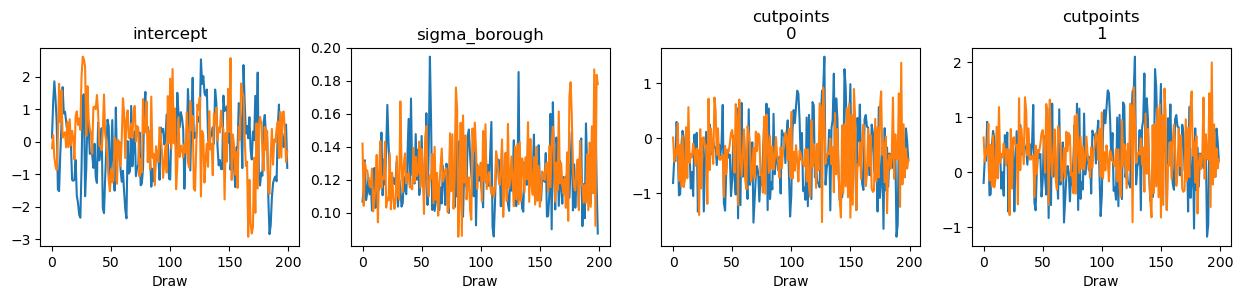

In [34]:
az.plot_trace(
    trace,
    var_names=[
        "intercept",
        "sigma_borough",
        "cutpoints"
    ]
)